# Séance 1 · FHIR, échanger les données de santé
**Master 2 Data Science en santé · Université de Lille · samedi 17 octobre 2026**
Antoine Teston · antoine.teston@univ-lille.fr

Ce notebook suit la séance :

| Partie | Contenu | Données |
|---|---|---|
| A · parties 01 et 02 | Exercices courts : écrire, valider et interroger des ressources | exemples du cours, serveur HAPI |
| B · partie 03 | TP 1 : interroger un serveur FHIR en Python | serveur public HAPI |
| C · partie 04 | TP 2 : d'un export FHIR à un mini-entrepôt OMOP | fichiers `donnees/export_fhir/*.ndjson` |

Les cellules marquées `# À COMPLÉTER` contiennent des `...` à remplacer.
Toutes les données sont **fictives** ; n'écrivez jamais de données réelles sur le serveur public.

In [2]:
# Installation (une fois, depuis ce dossier) :
# pip install -r requirements.txt
import json
import requests
import pandas as pd
import duckdb
import fhir.resources
import fhirpathpy  # noqa: F401
import numpy as np
import matplotlib.pyplot as plt

BASE = "https://hapi.fhir.org/baseR4"
H = {"Accept": "application/fhir+json"}

# Vérification de l'environnement
version = lambda v: tuple(int(x) for x in v.split(".")[:2])
assert version(fhir.resources.__version__) >= (8, 0),     f"fhir.resources {fhir.resources.__version__} trop ancien : pip install -U -r requirements.txt"
assert version(duckdb.__version__) >= (1, 1),     f"duckdb {duckdb.__version__} trop ancien : pip install -U -r requirements.txt"
import os
assert os.path.exists("donnees/export_fhir"), "Ouvrez le notebook depuis le dossier seance1_fhir"
print("Environnement OK · fhir.resources", fhir.resources.__version__,
      "· duckdb", duckdb.__version__, "· pandas", pd.__version__)

# Style des graphiques : une couleur par laboratoire, toujours la même
COULEURS = {"mg/dL": "#2a78d6", "g/L": "#eb6834", "mmol/L": "#1baf7a"}
ENCRE, GRIS = "#2b2b29", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 3.8), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRIS,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": ENCRE, "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})

Environnement OK · fhir.resources 8.3.0 · duckdb 1.5.6 · pandas 3.0.3


---
## A · Exercices des parties 01 et 02

### A1 · Écrire et valider une ressource (partie 01 · 8 min)
Voici l'Observation de la slide « Exemple : une ressource Observation ».
1. Écrivez `obs2` : la glycémie de la **même patiente**, mesurée **le lendemain** à 8 h 10, à **1,26 g/L**.
2. Validez-la avec `fhir.resources`, qui vérifie la structure d'une ressource FHIR.
3. Ajoutez l'élément qui rattache la mesure au séjour `Encounter/sejour-001`.

In [3]:
obs1 = {
    "resourceType": "Observation",
    "id": "obs-glycemie-01",
    "status": "final",
    "code": {"coding": [{"system": "http://loinc.org", "code": "2345-7",
                         "display": "Glucose [Mass/volume] in Serum or Plasma"}]},
    "subject": {"reference": "Patient/exemple-p001"},
    "effectiveDateTime": "2026-09-01T08:30:00+02:00",
    "valueQuantity": {"value": 0.97, "unit": "g/L",
                      "system": "http://unitsofmeasure.org", "code": "g/L"},
}

In [4]:
from fhir.resources.R4B.observation import Observation   # modèles FHIR R4B (proches de R4)

# À COMPLÉTER
obs2 = {
    "resourceType": "Observation",
    "id": "obs-glycemie-02",
    "status": "final",
    "code": obs1["code"],
    "subject": {"reference": "Patient/exemple-p001"},
    # question 3 : quel élément pour le séjour ?
    "effectiveDateTime": "2026-09-02T08:30:00+02:00",
    "valueQuantity": {"value": 1.26, "unit": "g/L",
                      "system": "http://unitsofmeasure.org", "code": "g/L"},
}
o = Observation.model_validate(obs2)
print("Ressource valide :", o.id, o.valueQuantity.value, o.valueQuantity.unit)

Ressource valide : obs-glycemie-02 1.26 g/L


**Et si on se trompe ?** Lancez la cellule suivante : deux erreurs, deux comportements différents.
Laquelle est détectée, laquelle passe ? Pourquoi ?

In [5]:
# À lancer une fois obs2 complétée (A1)
from pydantic import ValidationError

essais = {
    "date au format français": {**obs2, "effectiveDateTime": "02/09/2026"},
    "statut inventé":          {**obs2, "status": "terminé"},
}
for nom, ressource in essais.items():
    try:
        Observation.model_validate(ressource)
        print(f"{nom:25} -> acceptée")
    except ValidationError as e:
        print(f"{nom:25} -> refusée :", e.errors()[0]["msg"][:60])

date au format français   -> refusée : Value error, DateTime value string does not match spec regex
statut inventé            -> acceptée


### A2 · Exécuter une recherche (partie 02 · 5 min)
Sur la slide « Décoder une requête », vous avez lu une recherche. Exécutez-la maintenant.
1. Lancez la recherche des 5 glycémies les plus récentes du serveur (`_sort=-date`, `_count=5`).
2. Affichez le type du Bundle, le nombre d'entrées et la date de chaque mesure.
3. Relancez-la pour **un seul patient** : celui de la première entrée.

In [6]:
# À COMPLÉTER
params = {"code": "http://loinc.org|2345-7", "_sort": "-date", "_count": 5}
try:
    b = requests.get(f"{BASE}/Observation", params=params, headers=H, timeout=30).json()
    if b["resourceType"] == "OperationOutcome":          # le serveur explique l'erreur
        raise ValueError(b["issue"][0]["diagnostics"])
    print(b["type"], len(b.get("entry", [])), "entrées")
    for e in b.get("entry", []):
        r = e["resource"]
        print(r["id"], r["effectiveDateTime"], r["subject"]["reference"])   # id, date, patient

    # 3. un seul patient : récupérez sa référence dans la première entrée
    patient = b["entry"][0]["resource"]["subject"]["reference"]
    b2 = requests.get(f"{BASE}/Observation", params={**params, "patient": patient},
                      headers=H, timeout=30).json()
    print("Patient", patient, ":", len(b2.get("entry", [])), "glycémie(s)")
except requests.RequestException as err:
    print("Serveur injoignable :", err)

searchset 5 entrées
125906 2026-10-13T23:20:00+02:00 Patient/125904
135753 2026-10-13T23:20:00+02:00 Patient/135751
135773 2026-10-13T23:20:00+02:00 Patient/135771
125916 2026-10-13T23:20:00+02:00 Patient/125914
125870 2026-10-13T23:20:00+02:00 Patient/125868
Patient Patient/125904 : 1 glycémie(s)


### A3 · FHIRPath en Python (partie 02 · 5 min)
1. Évaluez les quatre expressions de la slide FHIRPath sur `patient` et `obs1`.
2. Pourquoi `ofType(Quantity)` ne renvoie rien sans le paramètre `model` ?
3. Écrivez l'expression qui renvoie **le prénom** de la patiente, puis celle qui renvoie **la date** de la mesure.

In [10]:
from fhirpathpy import evaluate
from fhirpathpy.models import models

patient = {
    "resourceType": "Patient", "id": "exemple-p001",
    "identifier": [{"system": "urn:oid:1.2.250.1.213.1.4.8", "value": "2850759350123"}],
    "name": [{"use": "official", "family": "Dupont", "given": ["Marie"]}],
    "gender": "female", "birthDate": "1985-07-12",
}
R4 = models["r4"]   # le modèle R4 indique les types : nécessaire pour ofType(...)

for ressource, expr in [
    (patient, "Patient.name.where(use = 'official').family"),
    (patient, "Patient.identifier.where(system = 'urn:oid:1.2.250.1.213.1.4.8').value"),
    (obs1, "Observation.value.ofType(Quantity).value"),
    (obs1, "Observation.code.coding.where(system = 'http://loinc.org').code"),
]:
    print(f"{expr:75} -> sans modèle {evaluate(ressource, expr)} | avec {evaluate(ressource, expr, {}, R4)}")

Patient.name.where(use = 'official').family                                 -> sans modèle ['Dupont'] | avec ['Dupont']
Patient.identifier.where(system = 'urn:oid:1.2.250.1.213.1.4.8').value      -> sans modèle ['2850759350123'] | avec ['2850759350123']
Observation.value.ofType(Quantity).value                                    -> sans modèle [] | avec [Decimal('0.97')]
Observation.code.coding.where(system = 'http://loinc.org').code             -> sans modèle ['2345-7'] | avec ['2345-7']


In [13]:
# À COMPLÉTER
print(evaluate(patient, "Patient.name.where(use = 'official').given)"))           # le prénom
print(evaluate(obs1, "Observation.effectiveDateTime", {}, R4))      # la date de la mesure

['Marie']
['2026-09-01T08:30:00+02:00']


---
## B · TP 1 : interroger un serveur FHIR (partie 03)
Le code est celui des slides : exécutez, puis répondez aux questions « À faire » de chaque slide.
Remplacez `G3` par votre numéro de groupe.

Si la cellule ci-dessous affiche « injoignable » : vérifiez le réseau, ou lancez un serveur local
(`docker run -p 8080:8080 hapiproject/hapi:latest`) et utilisez `BASE = "http://localhost:8080/fhir"`.

In [14]:
# Étape 0 · Le serveur répond-il ?
try:
    requests.get(f"{BASE}/metadata", params={"_summary": "true"}, headers=H, timeout=15).raise_for_status()
    print("Serveur joignable :", BASE)
except requests.RequestException as err:
    print("Serveur injoignable :", BASE)
    print(err)

Serveur joignable : https://hapi.fhir.org/baseR4


In [15]:
# Étape 1 · Ce que sait faire le serveur
cap = requests.get(f"{BASE}/metadata", headers=H, timeout=30).json()
print(cap["fhirVersion"])
types = [r["type"] for r in cap["rest"][0]["resource"]]
print(len(types), types[:8])

4.0.1
146 ['Account', 'ActivityDefinition', 'AdverseEvent', 'AllergyIntolerance', 'Appointment', 'AppointmentResponse', 'AuditEvent', 'Basic']


In [16]:
# Étape 2 · Rechercher des patients
r = requests.get(f"{BASE}/Patient", params={"family": "Martin", "_count": 5},
                 headers=H, timeout=30)
bundle = r.json()
print(bundle["type"], bundle.get("total"))
for e in bundle.get("entry", []):
    p = e["resource"]
    print(p["id"], p.get("gender"), p.get("birthDate"))

searchset None
68874 female 2021-06-21
76691 female 2021-06-21
82177 female 2021-06-21
92783 female 2021-06-21
94995 female 2021-06-21


In [17]:
# Étape 3 · Créer un patient et sa glycémie en une transaction
import uuid
pid = f"urn:uuid:{uuid.uuid4()}"
patient_tp = {"resourceType": "Patient", "gender": "female",
              # identifiant unique : le serveur refuse (412) une copie exacte d'un patient existant
              "identifier": [{"system": "urn:m2dss", "value": str(uuid.uuid4())}],
              "name": [{"family": "M2DSS-G3", "given": ["Test"]}]}
obs_tp = {"resourceType": "Observation", "status": "final",
          "code": {"coding": [{"system": "http://loinc.org", "code": "2345-7"}]},
          "subject": {"reference": pid},
          "valueQuantity": {"value": 0.97, "unit": "g/L",
                            "system": "http://unitsofmeasure.org", "code": "g/L"}}
tx = {"resourceType": "Bundle", "type": "transaction", "entry": [
    {"fullUrl": pid, "resource": patient_tp, "request": {"method": "POST", "url": "Patient"}},
    {"resource": obs_tp, "request": {"method": "POST", "url": "Observation"}}]}
r = requests.post(BASE, json=tx, timeout=30,
                  headers={"Content-Type": "application/fhir+json", "Accept": "application/fhir+json"})
reponse = r.json()
if r.ok:
    print(r.status_code, [e["response"]["location"] for e in reponse["entry"]])
else:   # le serveur renvoie un OperationOutcome qui explique le refus
    print(r.status_code, "refusé :", [i.get("diagnostics") for i in reponse.get("issue", [])])

200 ['Patient/140695/_history/1', 'Observation/140696/_history/1']


In [18]:
# Étape 4 · Suivre la pagination
def tout_lire(url, params=None, limite=500):
    n = 0
    while url and n < limite:
        b = requests.get(url, params=params, headers=H, timeout=30).json()
        for e in b.get("entry", []):
            n += 1
            yield e["resource"]
        url = next((l["url"] for l in b.get("link", [])
                    if l["relation"] == "next"), None)
        params = None

In [19]:
# Étape 5 · Aplatir en tableau pour l'analyse
obs = tout_lire(f"{BASE}/Observation",
                {"code": "http://loinc.org|2345-7", "_count": 100})
df = pd.DataFrame([{
    "patient": o["subject"]["reference"],
    "date": o.get("effectiveDateTime"),
    "valeur": o.get("valueQuantity", {}).get("value"),
    "unite": o.get("valueQuantity", {}).get("unit"),
} for o in obs if "subject" in o])
print(df["unite"].value_counts())

unite
mg/dL     484
g/L         4
mmol/L      2
Name: count, dtype: int64


**Étape 5 bis · Le serveur public en image.** Chaque point est une glycémie du serveur, rangée par unité.
Que remarquez-vous ? Une valeur vous paraît-elle impossible ?

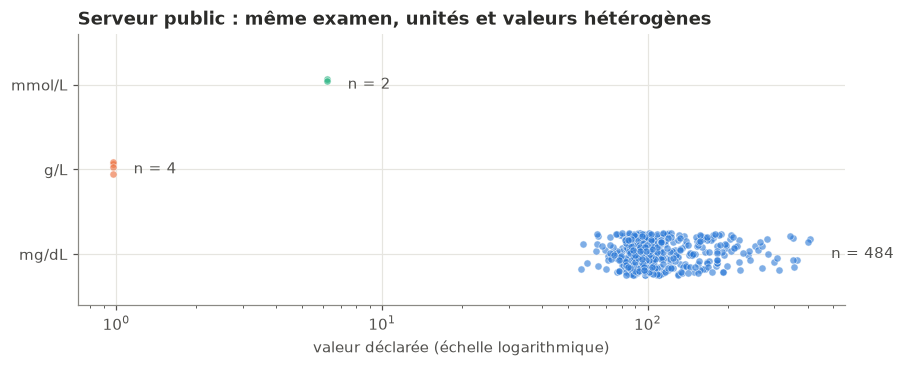

In [20]:
assert "df" in globals(), "Lancez d'abord l'étape 5 (réseau nécessaire)"
v = df.assign(unite=df["unite"].fillna("(sans unité)")).dropna(subset=["valeur"])
v = v[pd.to_numeric(v["valeur"], errors="coerce") > 0]
unites = v["unite"].value_counts().index.tolist()
fig, ax = plt.subplots(figsize=(9, 1.4 + 0.6 * len(unites)))
rng = np.random.default_rng(0)
for i, u in enumerate(unites):
    x = v.loc[v["unite"] == u, "valeur"].astype(float)
    ax.scatter(x, i + rng.uniform(-0.25, 0.25, len(x)), s=22, color=COULEURS.get(u, GRIS),
               alpha=0.6, edgecolors="white", linewidths=0.5)
    ax.text(x.max() * 1.2, i, f"n = {len(x)}", va="center", color="#52514e")
ax.set_xscale("log")
ax.set_yticks(range(len(unites)), unites)
ax.set_ylim(-0.6, len(unites) - 0.4)
ax.set_xlabel("valeur déclarée (échelle logarithmique)")
ax.set_title("Serveur public : même examen, unités et valeurs hétérogènes")
plt.show()

---
## C · TP 2 : d'un export FHIR à un mini-entrepôt OMOP (partie 04 · 25 min)

`donnees/export_fhir/` contient ce que renverrait un `$export` (Bulk Data) d'un hôpital fictif :
un fichier NDJSON par type de ressource (`Patient`, `Observation`, `Condition`).
Objectif : construire les tables OMOP **PERSON** et **MEASUREMENT** pour les glycémies, avec DuckDB,
puis répondre à une question clinique.

Les identifiants de concepts utiles sont dans `donnees/concepts.csv`
(extrait pédagogique : **à vérifier dans Athena** avant tout usage réel).

In [21]:
con = duckdb.connect()   # base en mémoire
D = "donnees/export_fhir"
for t in ["Patient", "Observation", "Condition"]:
    con.sql(f"create or replace view fhir_{t.lower()} as "
            f"select * from read_json('{D}/{t}.ndjson', format='newline_delimited')")
    print(t, con.sql(f"select count(*) from fhir_{t.lower()}").fetchone()[0])

concepts = pd.read_csv("donnees/concepts.csv")
concepts

Patient 150
Observation 984
Condition 55


,concept_id,concept_name,domain_id,vocabulary_id,concept_code,usage_dans_le_tp
0,8507,MALE,Gender,Gender,M,PERSON.gender_concept_id
1,8532,FEMALE,Gender,Gender,F,PERSON.gender_concept_id
2,3004501,Glucose [Mass/volume] in Serum or Plasma,Measurement,LOINC,2345-7,MEASUREMENT.measurement_concept_id
3,3013826,Glucose [Moles/volume] in Serum or Plasma,Measurement,LOINC,14749-6,MEASUREMENT.measurement_concept_id (variante s...
4,8840,milligram per deciliter,Unit,UCUM,mg/dL,MEASUREMENT.unit_concept_id
5,32817,EHR,Type Concept,Type Concept,NaN,MEASUREMENT.measurement_type_concept_id


### C1 · Explorer (3 min)
DuckDB lit le JSON imbriqué : `code.coding[1].code` désigne le premier code (les listes commencent à 1).
Comptez les observations par code LOINC, unité et statut. Que remarquez-vous ?

In [28]:
# À COMPLÉTER
con.sql('''
    select code.coding[1].code  as loinc,
           code.coding[1].display as unite,
           status,
           count(*)            as n
    from fhir_observation
    group by all
    order by n desc
''').df()

,loinc,unite,status,n
0,2345-7,Glucose [Mass/volume] in Serum or Plasma,final,656
1,14749-6,Glucose [Moles/volume] in Serum or Plasma,final,179
2,4548-4,Hemoglobin A1c/Hemoglobin.total in Blood,final,117
3,2345-7,Glucose [Mass/volume] in Serum or Plasma,cancelled,20
4,2345-7,Glucose [Mass/volume] in Serum or Plasma,entered-in-error,8
5,14749-6,Glucose [Moles/volume] in Serum or Plasma,cancelled,4


> Trois laboratoires, trois habitudes : mg/dL et g/L (LOINC 2345-7), mmol/L (LOINC 14749-6).
> Il y a aussi des HbA1c (4548-4), un autre examen, et des mesures annulées ou saisies par erreur.

**C1 bis · Voir le problème (1 min).** Lancez la cellule : chaque point est une glycémie, rangée par unité.
Pourquoi une moyenne calculée directement sur `valueQuantity.value` n'aurait-elle aucun sens ?

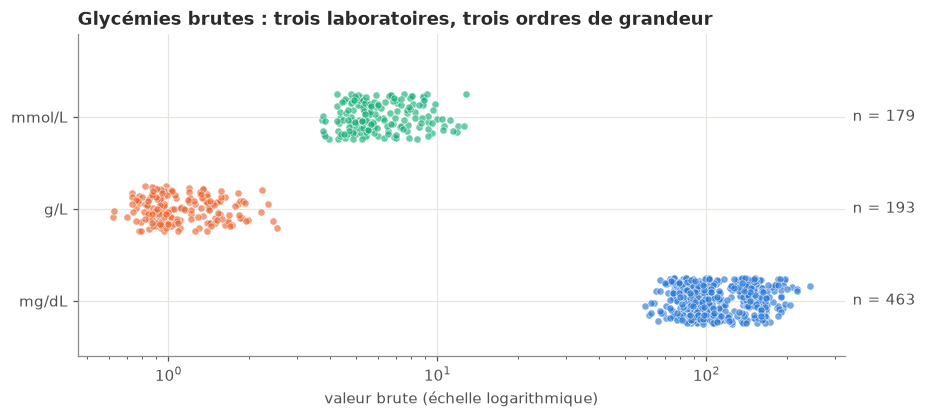

In [ ]:
brut = con.sql('''
    select valueQuantity.code as unite, valueQuantity.value as valeur
    from fhir_observation
    where status = 'final' and code.coding[1].code in ('2345-7', '14749-6')
''').df()

def nuage(data, col_unite, col_valeur, titre, xlabel, log=False, seuil=None):
    fig, ax = plt.subplots()
    rng = np.random.default_rng(0)
    for i, (unite, couleur) in enumerate(COULEURS.items()):
        x = data.loc[data[col_unite] == unite, col_valeur]
        ax.scatter(x, i + rng.uniform(-0.25, 0.25, len(x)), s=22, color=couleur,
                   alpha=0.65, edgecolors="white", linewidths=0.5)
        ax.text(1.01, i, f"n = {len(x)}", transform=ax.get_yaxis_transform(), va="center", color="#52514e")
    if seuil:
        ax.axvline(seuil, color=ENCRE, lw=1.5, ls="--")
        ax.text(seuil, 2.5, f" {seuil} mg/dL", color=ENCRE, va="bottom")
    if log:
        ax.set_xscale("log")
    ax.set_yticks(range(3), list(COULEURS))
    ax.set_ylim(-0.6, 2.9)
    ax.set_xlabel(xlabel)
    ax.set_title(titre)
    plt.show()

nuage(brut, "unite", "valeur", "Glycémies brutes : trois laboratoires, trois ordres de grandeur",
      "valeur brute (échelle logarithmique)", log=True)



# Une moyenne calculée directement sur les valeurs brutes n'aurait pas de sens car les unités de mesures ne sont pas les mêmes.

### C2 · Aplatir et harmoniser les glycémies (8 min)
Créez `stg_glycemie` : une ligne par glycémie **exploitable**, valeur convertie en **mg/dL**.
- garder les statuts `final`, les codes 2345-7 et 14749-6, les valeurs non nulles ;
- conversions : 1 g/L = 100 mg/dL ; 1 mmol/L = 18,016 mg/dL (masse molaire du glucose : 180,16 g/mol) ;
- garder la valeur, l'unité et le code d'origine : en OMOP, on trace toujours la source.

In [32]:
# À COMPLÉTER
con.sql('''
    create or replace table stg_glycemie as
    select id                                         as observation_id,
           split_part(subject.reference, '/', 2)     as patient_fhir_id,
           cast(effectiveDateTime as timestamp)       as mesure_le,
           code.coding[1].code                        as loinc_source,
           valueQuantity.value                        as valeur_source,
           valueQuantity.code                         as unite_source,
           round(case valueQuantity.code
                   when 'mg/dL' then valueQuantity.value
                   when 'g/L' then ValueQuantity.value * 100
                   when 'mmol/L' then ValueQuantity.value * 18.016
                 end, 1)                              as valeur_mg_dl
    from fhir_observation
    where status = 'final' and code.coding[1].code in ('2345-7','14749-6')
''')
con.sql("select unite_source, count(*) n, round(avg(valeur_mg_dl),1) moyenne_mg_dl "
        "from stg_glycemie group by 1 order by 1").df()

,unite_source,n,moyenne_mg_dl
0,g/L,193,115.8
1,mg/dL,463,115.9
2,mmol/L,179,114.2


**Contrôle** : après conversion, les moyennes des trois laboratoires doivent être du même ordre de grandeur.
Si l'une est 100 fois trop petite, la conversion est fausse.

**C2 bis · Vérifier en image (1 min).** Même graphique après conversion : les trois laboratoires doivent se superposer.

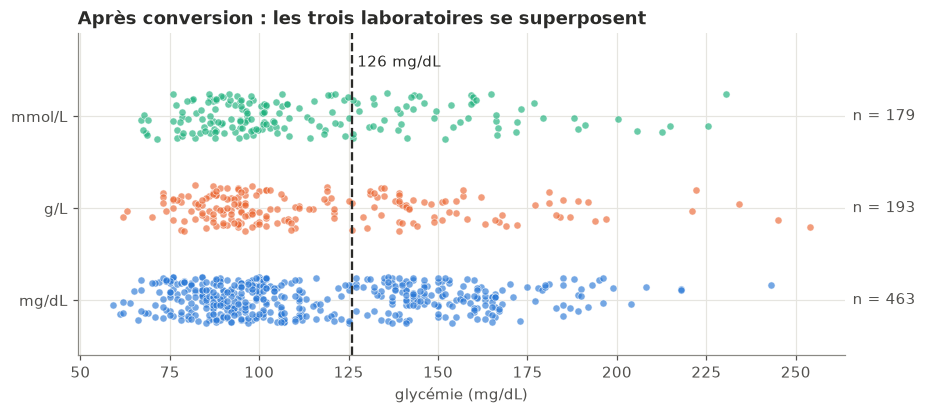

In [33]:
g = con.sql("select unite_source, valeur_mg_dl from stg_glycemie").df()
nuage(g, "unite_source", "valeur_mg_dl", "Après conversion : les trois laboratoires se superposent",
      "glycémie (mg/dL)", seuil=126)

### C3 · Construire PERSON (5 min)
Colonnes attendues : `person_id` (entier), `gender_concept_id`, `year_of_birth`, `month_of_birth`,
`day_of_birth`, `birth_datetime`, `race_concept_id` et `ethnicity_concept_id` (0 : non renseigné en France),
`person_source_value` (l'id FHIR), `gender_source_value`.

In [37]:
# À COMPLÉTER
con.sql('''
    create or replace table person as
    select cast(split_part(id, '-', 2) as integer)   as person_id,
           case gender when 'male' then 1
                       when 'female' then 2
                       else 0 end                     as gender_concept_id,
           year(cast(Birthdate as date))              as year_of_birth,
           month(cast(Birthdate as date))             as month_of_birth,
           day(cast(Birthdate as date))               as day_of_birth,
           cast(birthDate as timestamp)               as birth_datetime,
           0                                          as race_concept_id,
           0                                          as ethnicity_concept_id,
           id                                         as person_source_value,
           gender                                     as gender_source_value
    from fhir_patient
''')
con.sql("select * from person limit 5").df()

,person_id,gender_concept_id,year_of_birth,month_of_birth,day_of_birth,birth_datetime,race_concept_id,ethnicity_concept_id,person_source_value,gender_source_value
0,1,2,1976,11,24,1976-11-24,0,0,p-0001,female
1,2,1,1967,4,22,1967-04-22,0,0,p-0002,male
2,3,1,1990,2,9,1990-02-09,0,0,p-0003,male
3,4,2,1961,4,17,1961-04-17,0,0,p-0004,female
4,5,2,1978,12,30,1978-12-30,0,0,p-0005,female


### C4 · Construire MEASUREMENT (5 min)
Une ligne par glycémie de `stg_glycemie`, jointe à PERSON par `person_source_value`.
Choix du TP : valeurs harmonisées en mg/dL, donc `measurement_concept_id = 3004501` et `unit_concept_id = 8840`
pour toutes les lignes ; la valeur, l'unité et le code d'origine vont dans les colonnes `*_source_value`.

In [38]:
# À COMPLÉTER
con.sql('''
    create or replace table measurement as
    select row_number() over (order by g.mesure_le, g.observation_id) as measurement_id,
           p.person_id,
           3004501                         as measurement_concept_id,
           cast(g.mesure_le as date)   as measurement_date,
           g.mesure_le                 as measurement_datetime,
           44818701                      as measurement_type_concept_id,
           g.valeur_mg_dl              as value_as_number,
           8840                         as unit_concept_id,
           g.loinc_source              as measurement_source_value,
           g.unite_source              as unit_source_value,
           cast(g.valeur_source as varchar) as value_source_value
    from stg_glycemie g
    join person p on p.person_source_value = g.patient_fhir_id
''')
print(con.sql("select count(*) from measurement").fetchone()[0], "lignes")
con.sql("select * from measurement limit 5").df()

835 lignes


,measurement_id,person_id,measurement_concept_id,measurement_date,measurement_datetime,measurement_type_concept_id,value_as_number,unit_concept_id,measurement_source_value,unit_source_value,value_source_value
0,1,6,3004501,2025-01-02,2025-01-02 06:05:00,44818701,164.8,8840,14749-6,mmol/L,9.15
1,2,64,3004501,2025-01-04,2025-01-04 07:20:00,44818701,115.0,8840,2345-7,mg/dL,115.0
2,3,105,3004501,2025-01-05,2025-01-05 08:17:00,44818701,82.3,8840,14749-6,mmol/L,4.57
3,4,79,3004501,2025-01-05,2025-01-05 08:35:00,44818701,119.0,8840,2345-7,g/L,1.19
4,5,30,3004501,2025-01-06,2025-01-06 06:31:00,44818701,138.0,8840,2345-7,g/L,1.38


### C5 · Une question clinique (4 min)
Critère de diabète retenu ici : **au moins deux glycémies à jeun ≥ 126 mg/dL** (1,26 g/L).
1. Combien de patients remplissent ce critère, à partir de MEASUREMENT uniquement ?
2. Parmi eux, combien n'ont **pas** de diagnostic de diabète dans `Condition` ?

In [39]:
# À COMPLÉTER
con.sql('''
    with critere as (
        select person_id
        from measurement
        where value_as_number >= 126
        group by person_id
        having count(*) > 1
    ),
    diagnostic as (
        select distinct split_part(subject.reference, '/', 2) as patient_fhir_id
        from fhir_condition
        where list_contains(list_transform(code.coding, c -> c.code), '44054006')
    )
    select count(*)                                   as patients_critere,
           count(*) filter (where d.patient_fhir_id is null) as sans_diagnostic
    from critere c
    join person p using (person_id)
    left join diagnostic d on d.patient_fhir_id = p.person_source_value
''').df()

,patients_critere,sans_diagnostic
0,59,9


> **À discuter** : sans la conversion d'unités, que donnerait le critère ≥ 126 sur les valeurs en g/L
> ou en mmol/L ? Une erreur silencieuse : aucune ligne ne serait retenue pour ces laboratoires.

**C5 bis · La carte des patients (2 min).** Chaque point est un patient : en abscisse sa glycémie médiane,
en ordonnée le nombre de ses glycémies ≥ 126 mg/dL. La zone grisée correspond au critère.
Qui sont les points orange dans la zone ? Et les points bleus en dehors ?

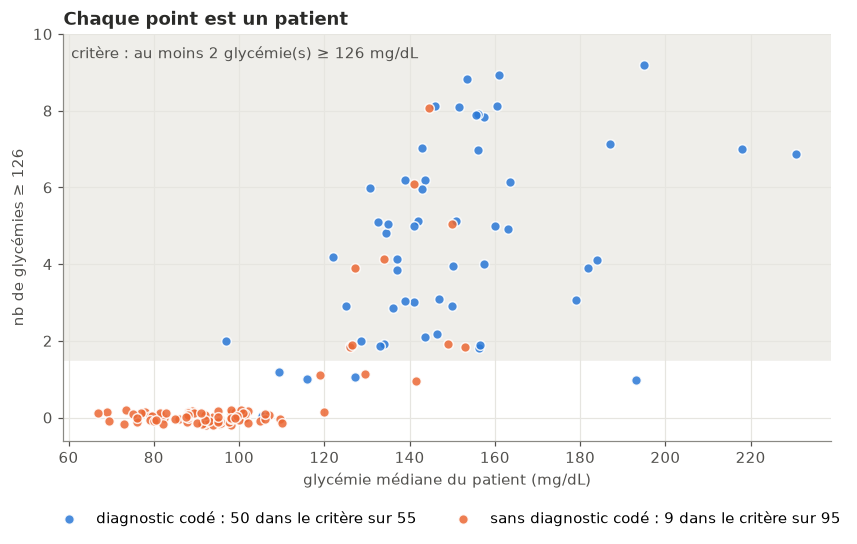

In [40]:
DIAG = {True: ("diagnostic codé", "#2a78d6"), False: ("sans diagnostic codé", "#eb6834")}

def carte_patients(seuil=126):
    return con.execute('''
        with diag as (
            select distinct split_part(subject.reference, '/', 2) as patient_fhir_id
            from fhir_condition
            where list_contains(list_transform(code.coding, c -> c.code), '44054006')
        )
        select p.person_source_value                          as patient,
               median(m.value_as_number)                      as mediane,
               count(*) filter (where m.value_as_number >= ?) as n_hautes,
               d.patient_fhir_id is not null                  as diagnostic
        from measurement m
        join person p using (person_id)
        left join diag d on d.patient_fhir_id = p.person_source_value
        group by all
        order by patient
    ''', [seuil]).df()

def tracer_carte(carte, seuil=126, nb_min=2):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    haut = carte["n_hautes"].max() + 1
    ax.axhspan(nb_min - 0.5, haut, color="#efeeea", zorder=0)
    ax.text(0.01, 0.97, f"critère : au moins {nb_min} glycémie(s) ≥ {seuil} mg/dL",
            transform=ax.transAxes, color="#52514e", va="top")
    rng = np.random.default_rng(1)
    for diag, (nom, couleur) in DIAG.items():
        c = carte[carte["diagnostic"] == diag]
        dedans = int((c["n_hautes"] >= nb_min).sum())
        ax.scatter(c["mediane"], c["n_hautes"] + rng.uniform(-0.2, 0.2, len(c)), s=40, color=couleur,
                   alpha=0.85, edgecolors="white", linewidths=1,
                   label=f"{nom} : {dedans} dans le critère sur {len(c)}")
    ax.set_ylim(-0.6, haut)
    ax.set_xlabel("glycémie médiane du patient (mg/dL)")
    ax.set_ylabel(f"nb de glycémies ≥ {seuil}")
    ax.set_title("Chaque point est un patient")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncols=2)
    plt.show()

carte = carte_patients(126)
tracer_carte(carte)

### C6 · Sauvegarder (1 min)
Les tables sont exportées en Parquet : ce sont elles que le pipeline de la **séance 2** produira chaque jour.

In [41]:
import os
os.makedirs("sortie", exist_ok=True)
for t in ["person", "measurement"]:
    con.sql(f"copy {t} to 'sortie/{t}.parquet' (format parquet)")
print(sorted(os.listdir("sortie")))

['measurement.parquet', 'person.parquet']


---
## D · Explorer (bonus : en fin de TP ou à la maison)

### D1 · Jouer avec le critère
Déplacez les curseurs. Avec un seuil à 110 mg/dL, combien de patients sans diagnostic entrent dans le critère ?
Pourquoi le choix du seuil est-il une décision clinique, et non une décision technique ?

In [ ]:
try:
    from ipywidgets import interact, IntSlider
    interact(lambda seuil, nb_min: tracer_carte(carte_patients(seuil), seuil, nb_min),
             seuil=IntSlider(value=126, min=100, max=200, step=2, description="seuil"),
             nb_min=IntSlider(value=2, min=1, max=5, description="nb min"))
except ImportError:
    print("ipywidgets absent (pip install ipywidgets). Version fixe, seuil 110 :")
    tracer_carte(carte_patients(110), 110, 2)

# 17 patients dans le critère

# Ce seuil est une décision clinique, qui suis-je pour donner mon avis de non-clinicien sur la glycémie des gens ? Un spécialiste sait ou se situe le seuil.

interactive(children=(IntSlider(value=126, description='seuil', max=200, min=100, step=2), IntSlider(value=2, …

### D2 · Un patient à la loupe
`courbe(...)` trace les glycémies d'un patient, colorées par laboratoire d'origine.
Regardez un patient au critère **sans** diagnostic : que diriez-vous à son médecin traitant ?

Au critère, sans diagnostic codé : p-0100, p-0058, p-0020, p-0019, p-0105, p-0089, p-0132, p-0134, p-0142


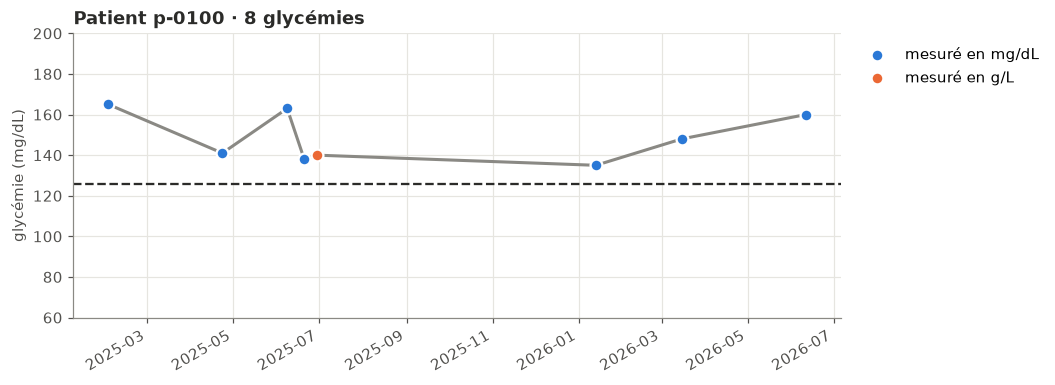

In [43]:
def courbe(patient_fhir_id):
    d = con.execute('''
        select mesure_le, valeur_mg_dl, unite_source
        from stg_glycemie
        where patient_fhir_id = ?
        order by mesure_le
    ''', [patient_fhir_id]).df()
    fig, ax = plt.subplots()
    ax.plot(d["mesure_le"], d["valeur_mg_dl"], color=GRIS, lw=2, zorder=1)
    for unite, couleur in COULEURS.items():
        s = d[d["unite_source"] == unite]
        if len(s):
            ax.scatter(s["mesure_le"], s["valeur_mg_dl"], s=60, color=couleur, edgecolors="white",
                       linewidths=1.5, zorder=2, label=f"mesuré en {unite}")
    ax.axhline(126, color=ENCRE, lw=1.5, ls="--")
    ax.set_ylim(min(60, d["valeur_mg_dl"].min() - 10), max(200, d["valeur_mg_dl"].max() + 15))
    ax.set_ylabel("glycémie (mg/dL)")
    ax.set_title(f"Patient {patient_fhir_id} · {len(d)} glycémies")
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.autofmt_xdate()
    plt.show()

a_signaler = (carte.query("n_hautes >= 2 and not diagnostic")
                   .sort_values(["n_hautes", "patient"], ascending=[False, True])["patient"].tolist())
print("Au critère, sans diagnostic codé :", ", ".join(a_signaler))
courbe(a_signaler[0])

### D3 · Défis
1. Quelle part des glycémies aurait échappé au seuil de 126 sans la conversion d'unités ?
2. Tracez la distribution des **HbA1c** (LOINC 4548-4). Combien de patients ont une HbA1c ≥ 6,5 % ?
   Combien d'entre eux sont sans diagnostic codé ? Qu'est-ce que cela dit de **qui** on dose ?
3. Quel patient a la glycémie la plus élevée ? Tracez sa courbe avec `courbe(...)`.


In [44]:
# Défi 1 · À vous
...

Ellipsis

In [45]:
# Défi 2 · À vous
...

Ellipsis

In [46]:
# Défi 3 · À vous
...

Ellipsis

### Pour aller plus loin
- **Variante sans conversion** : garder les mmol/L avec leur concept d'origine (3013826, voir `concepts.csv`).
  Quel choix facilite l'analyse ? Lequel respecte le mieux la source ?
- Construire **CONDITION_OCCURRENCE** à partir de `Condition.ndjson`.
- Vérifier dans **Athena** les identifiants de `concepts.csv`.